# Day 9 — Real-World Data Analysis
Today we'll apply what you've learned from NumPy, Pandas, Matplotlib, and Seaborn to a realistic data analysis project. We'll work gradually in Jupyter Notebook using your preferred format: **Explanation** → **Code** → **Output** → **Practice**.

<div align="center">
	<img src="../Images/Seaborn_34.png" alt="Real Data Plots" style="border-radius: 20px; width: 100%"
</div>

# Project: Restaurant Tips Analysis
We'll analyze the Seaborn tips dataset to discover what affects restaurant tips, compare customer groups, and communicate findings through visualizations.

## Today's learning goals
By the end of Day 9, you'll be able to:
- Explore and clean a real-world-style dataset.
- Use Pandas groupby() to calculate meaningful statistics.
- Visualize relationships using scatterplots and regression plots.
- Compare categories with boxplots and barplots.
- Use a heatmap to examine correlations.
- Build a final multi-plot analysis dashboard and write conclusions.

## Steps
### Step 1 — Load and inspect the dataset
#### 1. Explanation
The `tips` dataset contains restaurant bills, tips, customer information, meal times, and party sizes. Before plotting, we should understand its structure and check for missing or duplicate records.

#### 2. Code

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = sns.load_dataset("tips")

# Preview the data
display(df.head())

# Inspect its structure
print("Dataset shape:", df.shape)
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Dataset shape: (244, 7)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB

Missing Values:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Duplicate rows: 1


### Step 2 — Exploratory Data Analysis (EDA)
#### 1. Explanation
EDA helps us understand a dataset before building visualizations or drawing conclusions. We'll investigate three questions:
- Bill distribution: What do restaurant bills typically look like?
- Tip distribution: Are tips concentrated around a particular range?
- Customer patterns: Do bill amounts and tips vary by meal time or day?

#### 2. Code — Summary statistics

In [2]:
# Basic statistics for numerical columns
display(df[["total_bill", "tip", "size"]].describe().round(2))

# Average tip and bill by meal time
meal_summary = (
    df.groupby("time", observed=True)
    .agg(
        average_bill=("total_bill", "mean"),
        average_tip=("tip", "mean"),
        number_of_tables=("tip", "size")
    )
    .round(2)
)

display(meal_summary)

# Average tip by day
day_summary = (
    df.groupby("day", observed=True)
    .agg(
        average_tip=("tip", "mean"),
        average_bill=("total_bill", "mean"),
        number_of_tables=("tip", "size")
    )
    .round(2)
)

display(day_summary)

,total_bill,tip,size
count,244.00,244.00,244.00
mean,19.79,3.00,2.57
std,8.90,1.38,0.95
min,3.07,1.00,1.00
25%,13.35,2.00,2.00
50%,17.80,2.90,2.00
75%,24.13,3.56,3.00
max,50.81,10.00,6.00


,average_bill,average_tip,number_of_tables
time,,,
Lunch,17.17,2.73,68
Dinner,20.80,3.10,176


,average_tip,average_bill,number_of_tables
day,,,
Thur,2.77,17.68,62
Fri,2.73,17.15,19
Sat,2.99,20.44,87
Sun,3.26,21.41,76


#### 3. Visualize the distributions

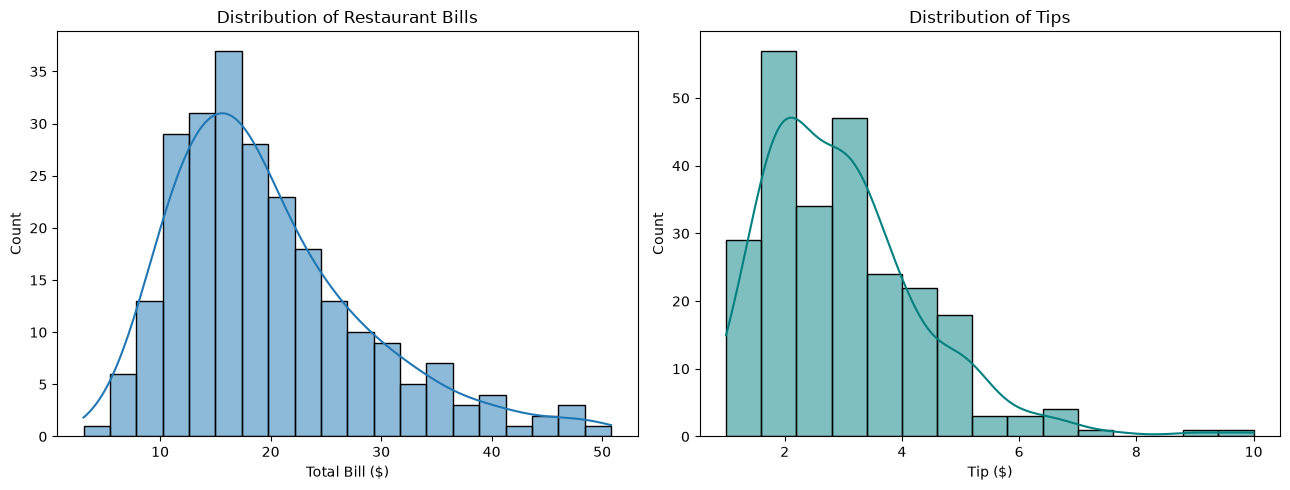

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Distribution of restaurant bills
sns.histplot(
    data=df,
    x="total_bill",
    bins=20,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Restaurant Bills")
axes[0].set_xlabel("Total Bill ($)")

# Distribution of tips
sns.histplot(
    data=df,
    x="tip",
    bins=15,
    kde=True,
    color="teal",
    ax=axes[1]
)

axes[1].set_title("Distribution of Tips")
axes[1].set_xlabel("Tip ($)")

plt.tight_layout()

plt.show()

#### 4. How to interpret the output
- `describe()` provides the mean, standard deviation, quartiles, minimum, and maximum.
- `groupby("time")` compares lunch and dinner observations.
- `groupby("day")` compares average tips and bills across days.
- `histplot()` shows how frequently values occur; `kde=True` overlays a smoothed density curve.

***Remember:*** **average tip amount is not the same as tip percentage.** A larger bill can produce a larger tip even when the customer tips a smaller percentage.

#### 5. Practice — Predict the result

In [4]:

from IPython.display import HTML, display

quiz_html = """
<div id="day9-step2-quiz" style="font-family: Arial, sans-serif; max-width: 750px; line-height: 1.7;">
    <p>Test your understanding of exploratory data analysis.</p>

    <form id="quiz-form">

        <div style="margin-bottom: 24px;">
            <p><b>Q1. What does df.describe() primarily provide for numerical columns?</b></p>
            <label><input type="radio" name="q1" value="a"> a) A list of unique values only</label><br>
            <label><input type="radio" name="q1" value="b"> b) Summary statistics such as mean and quartiles</label><br>
            <label><input type="radio" name="q1" value="c"> c) A correlation heatmap</label>
            <p id="feedback-q1"></p>
        </div>

        <div style="margin-bottom: 24px;">
            <p><b>Q2. What does df.groupby("time")["tip"].mean() calculate?</b></p>
            <label><input type="radio" name="q2" value="a"> a) The total tips for all customers, without separating meals</label><br>
            <label><input type="radio" name="q2" value="b"> b) The number of unique meal times</label><br>
            <label><input type="radio" name="q2" value="c"> c) The average tip separately for each meal time</label>
            <p id="feedback-q2"></p>
        </div>

        <div style="margin-bottom: 24px;">
            <p><b>Q3. If the average tip is higher at dinner, what can we conclude from that fact alone?</b></p>
            <label><input type="radio" name="q3" value="a"> a) Dinner customers always tip a higher percentage</label><br>
            <label><input type="radio" name="q3" value="b"> b) Dinner causes customers to tip more</label><br>
            <label><input type="radio" name="q3" value="c"> c) The average tip amount is higher at dinner, but the cause and tip percentage need further analysis</label>
            <p id="feedback-q3"></p>
        </div>

        <button type="button" id="submit-quiz"
            style="background:#2563eb; color:white; border:none; padding:10px 18px; border-radius:6px; cursor:pointer;">
            Submit Answers
        </button>

        <button type="button" id="reset-quiz"
            style="background:#e5e7eb; color:#111827; border:none; padding:10px 18px; border-radius:6px; cursor:pointer; margin-left:8px;">
            Reset
        </button>

        <h3 id="quiz-result"></h3>
    </form>

    <script>
    (function() {
        const root = document.getElementById("day9-step2-quiz");
        const answers = {
            q1: "b",
            q2: "c",
            q3: "c"
        };

        root.querySelector("#submit-quiz").addEventListener("click", function() {
            let score = 0;
            let unanswered = 0;

            Object.keys(answers).forEach(function(question) {
                const selected = root.querySelector(
                    'input[name="' + question + '"]:checked'
                );
                const feedback = root.querySelector("#feedback-" + question);

                if (!selected) {
                    unanswered++;
                    feedback.textContent = "Please select an answer.";
                    feedback.style.color = "#b45309";
                } else if (selected.value === answers[question]) {
                    score++;
                    feedback.textContent = "Correct! Well done.";
                    feedback.style.color = "#15803d";
                } else {
                    const explanations = {
                        q1: "describe() summarizes numerical data using statistics such as mean, standard deviation, and quartiles.",
                        q2: "groupby('time') separates observations by meal time before calculating the mean tip.",
                        q3: "A higher average tip amount does not establish a higher tip percentage or prove that meal time caused the difference."
                    };
                    feedback.textContent = "Not quite. " + explanations[question];
                    feedback.style.color = "#b91c1c";
                }
            });

            root.querySelector("#quiz-result").textContent =
                "Your score: " + score + "/3" +
                (unanswered ? " — " + unanswered + " question(s) unanswered." : "");
        });

        root.querySelector("#reset-quiz").addEventListener("click", function() {
            root.querySelector("#quiz-form").reset();

            ["q1", "q2", "q3"].forEach(function(question) {
                root.querySelector("#feedback-" + question).textContent = "";
            });

            root.querySelector("#quiz-result").textContent = "";
        });
    })();
    </script>
</div>
"""

display(HTML(quiz_html))


### Step 3 — Relationship Analysis
Our main question today is:

**Does a higher restaurant bill tend to be associated with a higher tip?**

We'll use a scatterplot to inspect individual observations and a regression plot to examine the overall trend.

#### 1. Scatterplot — Explore the relationship
**Explanation**\
`sns.scatterplot()` plots individual observations. Here, each point represents one restaurant bill and its corresponding tip.
- X-axis: `total_bill`
- Y-axis: `tip`
- `hue="time"`: colors observations by Lunch or Dinner.
- A positive association means tips generally tend to increase as bills increase; it does not mean every point follows that pattern.

**Code**

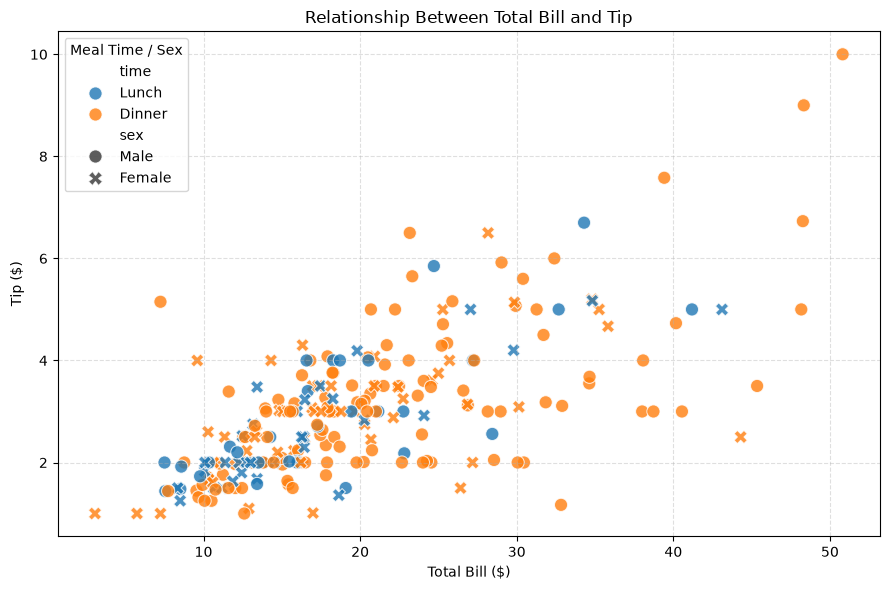

In [5]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="total_bill",
    y="tip",
    hue="time",
    style="sex",
    s=90,
    alpha=0.8
)

plt.title("Relationship Between Total Bill and Tip")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.grid(linestyle="--", alpha=0.4)

plt.legend(title="Meal Time / Sex")
plt.tight_layout()

plt.show()

**Expected interpretation**
You should generally see an upward trend: larger bills often correspond to larger tips. The points will still be scattered because customers do not all tip the same amount.

#### 2. Regression plot — Examine the trend
**Explanation**\
`sns.regplot()` adds a fitted regression line and, by default, a confidence interval around that estimated line.

It helps us visualize the overall linear relationship, but it does not prove that larger bills cause higher tips.

**Code**

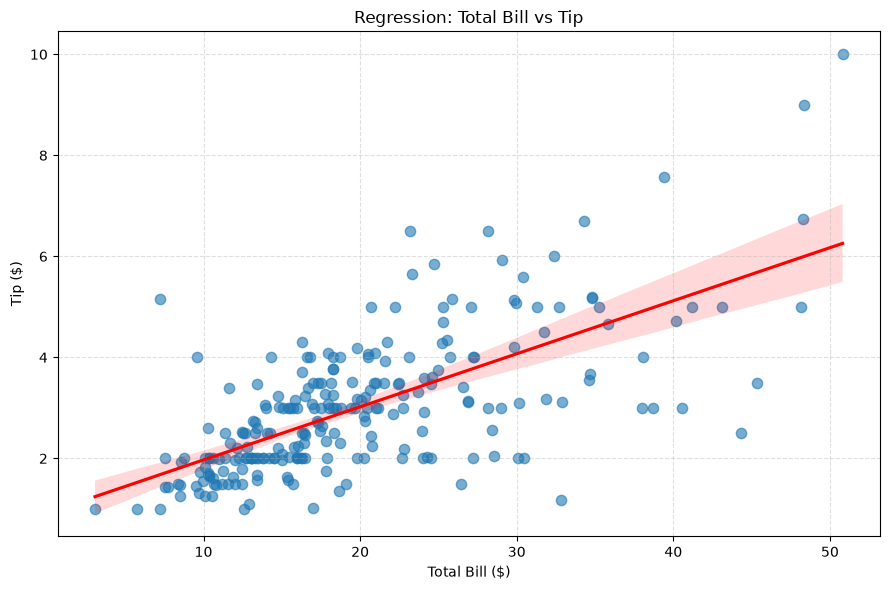

In [6]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=df,
    x="total_bill",
    y="tip",
    scatter_kws={"alpha": 0.6, "s": 55},
    line_kws={"color": "red"}
)

plt.title("Regression: Total Bill vs Tip")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.grid(linestyle="--", alpha=0.4)

plt.tight_layout()

plt.show()

**How to read it**
- **Upward-sloping line:** positive linear association.
- **Points close to the line:** the line describes those observations more closely.
- **Points far from the line:** actual tips differ from the fitted trend.
- **Confidence band:** uncertainty around the estimated regression line, not a range containing 95% of all individual tips.

#### 3. Calculate the correlation
Let's quantify the linear association with Pandas.

In [7]:
correlation = df["total_bill"].corr(df["tip"])

print(f"Correlation between total bill and tip: {correlation:.3f}")

Correlation between total bill and tip: 0.676


For the standard Seaborn `tips` dataset, the correlation is approximately 0.676, indicating a moderately strong positive linear association.

Correlation ranges from −1 to +1:
- Close to `+1`: strong positive linear association.
- Close to `0`: weak linear association.
- Close to `−1`: strong negative linear association.

Correlation alone does not establish causation, and a near-zero correlation does not rule out every possible nonlinear relationship.

#### 4. Practice — Predict the result

In [8]:

from IPython.display import HTML, display

quiz_html = """
<div id="day9-step3-quiz" style="font-family: Arial, sans-serif; max-width: 750px; line-height: 1.7;">

    <p>Test your understanding of scatterplots, regression plots, and correlation.</p>

    <form id="quiz-form">

        <div style="margin-bottom: 24px;">
            <p><b>Q1. What does each point in the scatterplot represent?</b></p>
            <label><input type="radio" name="q1" value="a"> a) An average tip for each meal time</label><br>
            <label><input type="radio" name="q1" value="b"> b) One observation pairing a total bill with its tip</label><br>
            <label><input type="radio" name="q1" value="c"> c) The correlation between two columns</label>
            <p id="feedback-q1"></p>
        </div>

        <div style="margin-bottom: 24px;">
            <p><b>Q2. What does a positive regression slope suggest in this example?</b></p>
            <label><input type="radio" name="q2" value="a"> a) Larger bills tend to be associated with larger tips</label><br>
            <label><input type="radio" name="q2" value="b"> b) Every customer tips the same percentage</label><br>
            <label><input type="radio" name="q2" value="c"> c) Larger bills cause larger tips in every case</label>
            <p id="feedback-q2"></p>
        </div>

        <div style="margin-bottom: 24px;">
            <p><b>Q3. What does a correlation of approximately +0.676 indicate?</b></p>
            <label><input type="radio" name="q3" value="a"> a) A perfect positive relationship</label><br>
            <label><input type="radio" name="q3" value="b"> b) A negative linear relationship</label><br>
            <label><input type="radio" name="q3" value="c"> c) A moderately strong positive linear association</label>
            <p id="feedback-q3"></p>
        </div>

        <button type="button" id="submit-quiz"
            style="background:#2563eb; color:white; border:none; padding:10px 18px; border-radius:6px; cursor:pointer;">
            Submit Answers
        </button>

        <button type="button" id="reset-quiz"
            style="background:#e5e7eb; color:#111827; border:none; padding:10px 18px; border-radius:6px; cursor:pointer; margin-left:8px;">
            Reset
        </button>

        <h3 id="quiz-result"></h3>
    </form>

    <script>
    (function() {
        const root = document.getElementById("day9-step3-quiz");

        const answers = {
            q1: "b",
            q2: "a",
            q3: "c"
        };

        const explanations = {
            q1: "Each point represents one observation, pairing a restaurant bill with its corresponding tip.",
            q2: "A positive slope indicates that larger bills tend to be associated with larger tips; it does not establish causation.",
            q3: "A correlation near +0.676 indicates a moderately strong positive linear association, not a perfect relationship."
        };

        root.querySelector("#submit-quiz").addEventListener("click", function() {
            let score = 0;
            let unanswered = 0;

            Object.keys(answers).forEach(function(question) {
                const selected = root.querySelector(
                    'input[name="' + question + '"]:checked'
                );
                const feedback = root.querySelector("#feedback-" + question);

                if (!selected) {
                    unanswered++;
                    feedback.textContent = "Please select an answer.";
                    feedback.style.color = "#b45309";
                } else if (selected.value === answers[question]) {
                    score++;
                    feedback.textContent = "Correct! " + explanations[question];
                    feedback.style.color = "#15803d";
                } else {
                    feedback.textContent = "Not quite. " + explanations[question];
                    feedback.style.color = "#b91c1c";
                }
            });

            root.querySelector("#quiz-result").textContent =
                "Your score: " + score + "/3" +
                (unanswered ? " — " + unanswered + " question(s) unanswered." : "");
        });

        root.querySelector("#reset-quiz").addEventListener("click", function() {
            root.querySelector("#quiz-form").reset();

            ["q1", "q2", "q3"].forEach(function(question) {
                root.querySelector("#feedback-" + question).textContent = "";
            });

            root.querySelector("#quiz-result").textContent = "";
        });
    })();
    </script>
</div>
"""

display(HTML(quiz_html))


### Step 4 — Categorical Comparisons
**Real-world question:** Do tip amounts differ by day, meal time, or customer group?

We'll use a boxplot to examine the distribution of tips across days and a barplot to compare average tips by meal time.

#### 1. Boxplot — Compare tips by day
**Explanation**
A boxplot helps us compare distributions across categories.
- **Middle line:** median tip.
- **Box:** middle 50% of observations (the interquartile range).
- **Whiskers and points:** show the spread and potential outliers, according to the plotting rule.

**Code**

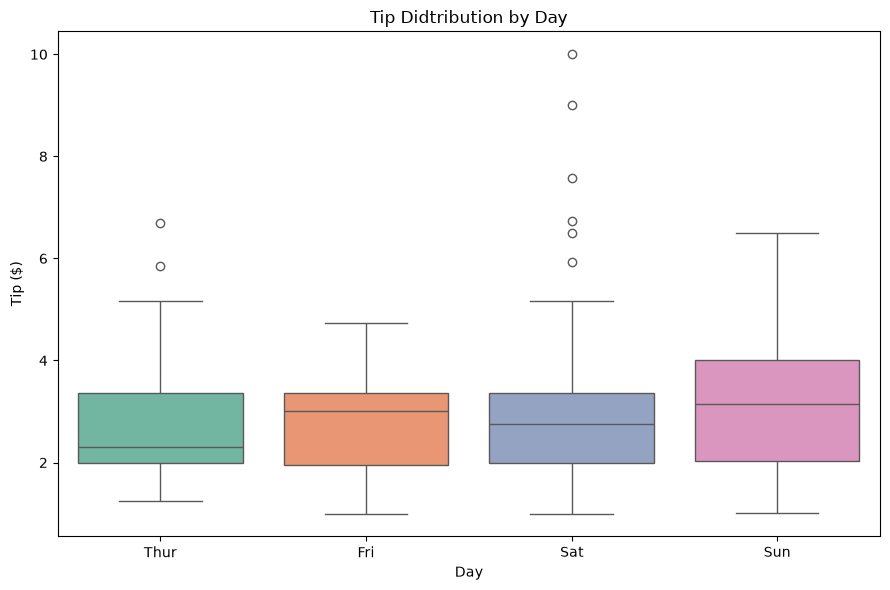

In [9]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="day",
    y="tip",
    hue="day",
    palette="Set2",
    legend=False,
    dodge=False
)

plt.title("Tip Didtribution by Day")
plt.xlabel("Day")
plt.ylabel("Tip ($)")

plt.tight_layout()

plt.show()

#### 2. Barplot — Compare average tips by meal time
**Explanation**
`sns.barplot()` estimates a summary statistic for each category. By default, it shows the mean and an uncertainty interval. We'll disable the interval here to make the mean comparisons easier to read.

**Code**

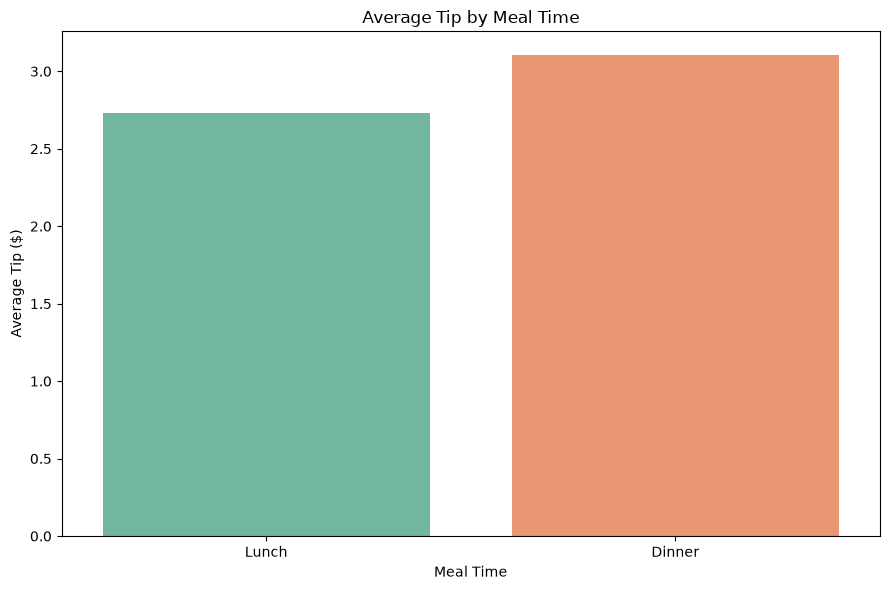

In [10]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=df,
    x="time",
    y="tip",
    hue="time",
    palette="Set2",
    errorbar=None,
    legend=False,
    dodge=False
)

plt.title("Average Tip by Meal Time")
plt.xlabel("Meal Time")
plt.ylabel("Average Tip ($)")

plt.tight_layout()

plt.show()

#### 3. Optional analysis — Compare tip percentages
A larger tip amount may simply reflect a larger bill. To compare tipping behavior more fairly, calculate the tip as a percentage of the total bill.

In [11]:
df["tip_percentage"] = (
    df["tip"] / df["total_bill"] * 100
)

tip_percentage_summary = (
    df.groupby("time", observed=True)["tip_percentage"]
      .mean()
      .round(2)
)

display(tip_percentage_summary)

time
Lunch     16.41
Dinner    15.95
Name: tip_percentage, dtype: float64

This gives the average of individual tip percentages for Lunch and Dinner. It is not the same as dividing the average tip by the average bill.

#### 4. Practice — Predict the result

In [12]:

from IPython.display import HTML, display

display(HTML("""
<div id="quiz-day9-step4" style="font-family:Arial,sans-serif;max-width:750px;padding:20px;border:1px solid #ddd;border-radius:12px;">
    <p>Topic: Categorical comparisons</p>

    <form id="quiz-form-day9-step4">

        <div style="margin-bottom:22px;">
            <p><b>Q1. What does the middle line inside a standard boxplot represent?</b></p>
            <label><input type="radio" name="q1" value="a"> A. Mean</label><br>
            <label><input type="radio" name="q1" value="b"> B. Median</label><br>
            <label><input type="radio" name="q1" value="c"> C. Maximum</label>
            <p id="feedback-q1"></p>
        </div>

        <hr>

        <div style="margin:22px 0;">
            <p><b>Q2. What does <code>errorbar=None</code> do in <code>sns.barplot()</code>?</b></p>
            <label><input type="radio" name="q2" value="a"> A. Hides the uncertainty interval</label><br>
            <label><input type="radio" name="q2" value="b"> B. Removes outliers</label><br>
            <label><input type="radio" name="q2" value="c"> C. Changes the mean to the median</label>
            <p id="feedback-q2"></p>
        </div>

        <hr>

        <div style="margin:22px 0;">
            <p><b>Q3. Why calculate tip percentage?</b></p>
            <label><input type="radio" name="q3" value="a"> A. To guarantee everyone pays the same tip</label><br>
            <label><input type="radio" name="q3" value="b"> B. To prove meal time causes higher tips</label><br>
            <label><input type="radio" name="q3" value="c"> C. To compare tips relative to bill size</label>
            <p id="feedback-q3"></p>
        </div>

        <button type="button" id="check-day9-step4"
            style="padding:10px 18px;border:0;border-radius:7px;background:#2563eb;color:white;cursor:pointer;">
            Check Answers
        </button>

        <button type="button" id="reset-day9-step4"
            style="padding:10px 18px;border:1px solid #aaa;border-radius:7px;background:transparent;cursor:pointer;margin-left:8px;">
            Reset
        </button>

        <h4 id="score-day9-step4"></h4>
        <p id="result-day9-step4"></p>
    </form>
</div>

<script>
(function() {
    const root = document.getElementById('quiz-day9-step4');
    const answers = {
        q1: {
            correct: 'b',
            explanation: 'The median is the middle value of the ordered data. The box shows the interquartile range (middle 50% of observations).'
        },
        q2: {
            correct: 'a',
            explanation: 'errorbar=None hides the uncertainty interval. It does not remove outliers or change the estimated mean.'
        },
        q3: {
            correct: 'c',
            explanation: 'Tip percentage = (tip / total_bill) × 100. It helps compare generosity relative to the size of each bill.'
        }
    };

    root.querySelector('#check-day9-step4').addEventListener('click', function() {
        let score = 0;
        let unanswered = 0;

        Object.keys(answers).forEach(function(q) {
            const selected = root.querySelector('input[name="' + q + '"]:checked');
            const feedback = root.querySelector('#feedback-' + q);

            if (!selected) {
                unanswered++;
                feedback.innerHTML = '<span style="color:#b45309;">Please answer this question.</span>';
                return;
            }

            if (selected.value === answers[q].correct) {
                score++;
                feedback.innerHTML = '<span style="color:#15803d;"><b>Correct!</b></span> ' + answers[q].explanation;
            } else {
                feedback.innerHTML = '<span style="color:#dc2626;"><b>Incorrect.</b></span> ' + answers[q].explanation;
            }
        });

        root.querySelector('#score-day9-step4').textContent =
            'Your score: ' + score + '/3';

        root.querySelector('#result-day9-step4').textContent =
            unanswered > 0
            ? 'Complete the unanswered question(s), then check again.'
            : score === 3
                ? 'Excellent! You are ready for Step 5: Correlation Analysis and the Final Dashboard.'
                : 'Review the explanations and try again.';
    });

    root.querySelector('#reset-day9-step4').addEventListener('click', function() {
        root.querySelector('#quiz-form-day9-step4').reset();
        ['q1', 'q2', 'q3'].forEach(function(q) {
            root.querySelector('#feedback-' + q).innerHTML = '';
        });
        root.querySelector('#score-day9-step4').textContent = '';
        root.querySelector('#result-day9-step4').textContent = '';
    });
})();
</script>
"""))


### Step 5 — Correlation analysis and the final dashboard
#### Part A: Correlation heatmap
A correlation matrix helps you examine the strength and direction of linear relationships between numerical columns.

**1. Calculate the correlation matrix**

In [13]:
# Select numerical columns only
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
correlation_matrix = numeric_df.corr()

display(correlation_matrix.round(3))

,total_bill,tip,size,tip_percentage
total_bill,1.000,0.676,0.598,-0.339
tip,0.676,1.000,0.489,0.342
size,0.598,0.489,1.000,-0.143
tip_percentage,-0.339,0.342,-0.143,1.000


Why select numerical columns?\
The `tips` dataset also contains categorical columns such as `sex`, `smoker`, `day`, and `time`. We want the numerical variables for this correlation analysis.

**2. Plot the heatmap**

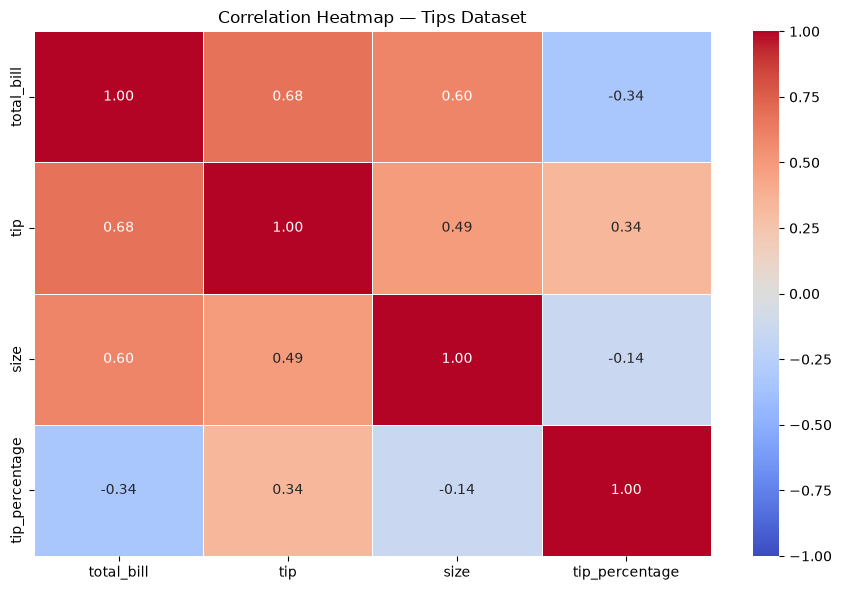

In [16]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    lw=0.5
    
)

plt.title("Correlation Heatmap — Tips Dataset")

plt.tight_layout()

plt.show()

**How to interpret it:**
- Values near `+1` indicate a strong positive linear relationship.
- Values near `−1` indicate a strong negative linear relationship.
- Values near `0` indicate a weak or absent linear relationship.
- Correlation does not prove causation.

For the standard Seaborn `tips` dataset, `total_bill` and `tip` have a correlation of approximately `+0.676`.

#### Part B: Build the final 2×2 dashboard
This dashboard combines four useful views of the dataset.

Before running the code, predict what each panel will reveal:
1. Scatterplot — relationship between bill amount and tip.
2. Boxplot — spread of tips across days.
3. Barplot — average tip by meal time.
4. Heatmap — correlations between numerical variables.

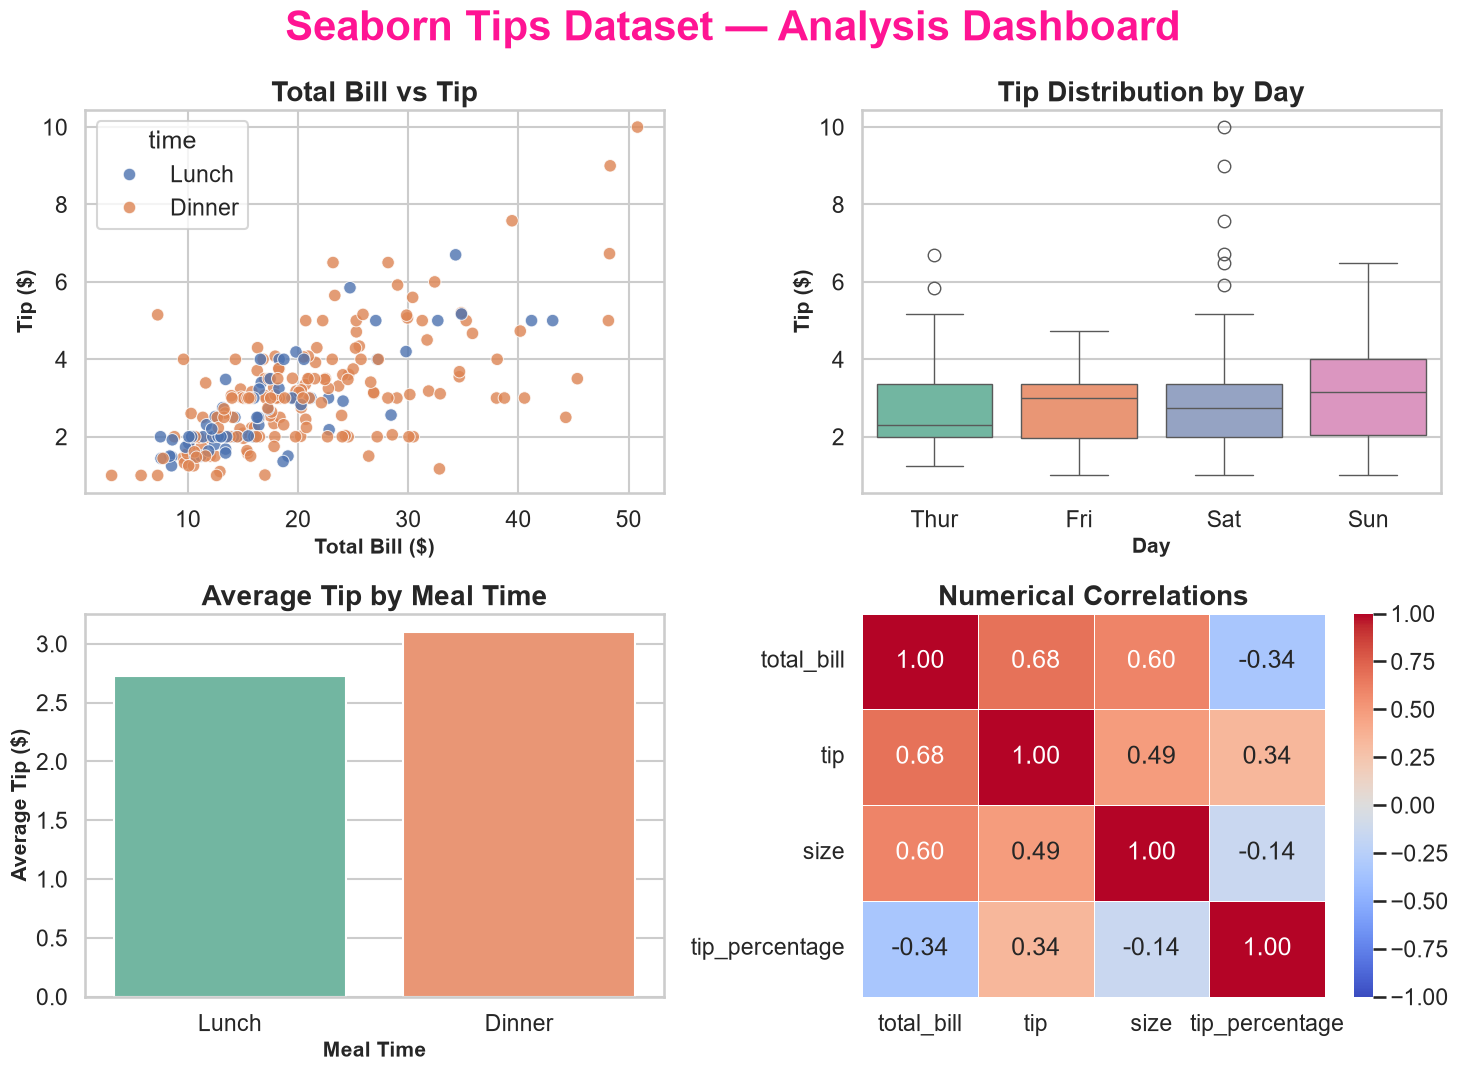

In [25]:
# Make sure tip_percentage exists
if "tip_percentage" not in df.columns:
    df["tip_percentage"] = df["tip"] / df["total_bill"] * 100

# Prepare corelation matrix
numeric_df = df.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()

# Create dashboard
sns.set_theme(style="whitegrid", context="talk")

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Bill vs tip
sns.scatterplot(
    data=df,
    x="total_bill",
    y="tip",
    hue="time",
    alpha=0.8,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Total Bill vs Tip", fontsize=20, fontweight="bold")
axes[0, 0].set_xlabel("Total Bill ($)", fontsize=15, fontweight="bold")
axes[0, 0].set_ylabel("Tip ($)", fontsize=15, fontweight="bold")

# 2. Tip distribution by day
sns.boxplot(
    data=df,
    x="day",
    y="tip",
    hue="day",
    palette="Set2",
    legend=False,
    dodge=False,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Tip Distribution by Day", fontsize=20, fontweight="bold")
axes[0, 1].set_xlabel("Day", fontsize=15, fontweight="bold")
axes[0, 1].set_ylabel("Tip ($)", fontsize=15, fontweight="bold")

# 3. Average tip by meal time
sns.barplot(
    data=df,
    x="time",
    y="tip",
    hue="time",
    palette="Set2",
    errorbar=None,
    legend=False,
    dodge=False,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Average Tip by Meal Time", fontsize=20, fontweight="bold")
axes[1, 0].set_xlabel("Meal Time", fontsize=15, fontweight="bold")
axes[1, 0].set_ylabel("Average Tip ($)", fontsize=15, fontweight="bold")

# 4. Correlation heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    lw=0.5,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Numerical Correlations", fontsize=20, fontweight="bold")

# Final formatting
fig.suptitle(
    "Seaborn Tips Dataset — Analysis Dashboard",
    fontsize=30,
    fontweight="bold",
    color="deeppink"
)

plt.tight_layout()

plt.show()

## Final Questions
Answer these three questions to complete Seaborn Day 9:
1. If the correlation between total_bill and tip is +0.676, what does that suggest?
2. Why might comparing tip_percentage be more informative than comparing tip amounts alone?
3. Why should you avoid concluding that dinner causes higher tips from this dataset?

**Answers:**\
Q1. A correlation of `+0.676` indicates a moderately strong positive linear relationship: larger bills tend to be associated with larger tips.

Q2. Tip percentage lets us compare tips relative to the amount of each bill, giving a fairer comparison of tipping rates across different bill sizes.

Q3. customers gives more tip at dinner time but the overall tip percentage by time is higher for Lunch time which suggests that customers give more percentage of tip based on the total bill during lunch.

<span style="color:green; font-weight:bold">A useful distinction</span>
These are two different metrics:
- **Average tip:** How much money customers leave on average.
- **Average tip percentage:** How large the tip is relative to the bill.

For example, a customer who leaves a `$100` tip on a `$2,000` bill tips `5%`, while a customer who leaves `$50` on a `$500` bill tips `10%`. The first customer leaves more money, but the second tips a larger percentage.

<span style="color:green; font-weight:bold">One important caution:</span> Even if dinner customers tip more on average, we cannot conclude that dinner causes higher tips. Bill size, party size, and other factors may contribute.